# Single-atom Imaging

Python companion to the AMO Toolkit page [Single-atom Imaging](https://amotoolkit.com/pages/imaging-calculator.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/imaging-calculator.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Species and the photon budget
Fluorescence from one atom: scattering rate $R = \frac{\Gamma}{2}\frac{s}{1+s+(2\Delta/\Gamma)^2}$, collection
$\eta_\mathrm{geo} = (1-\sqrt{1-\mathrm{NA}^2})/2$, then optical transmission and camera quantum efficiency.

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

ATOMS = {   # λ (nm), Γ/2π (MHz), I_sat (mW/cm²), D2 line
    "Rb87": (780.241, 6.065, 1.669), "Cs133": (852.347, 5.234, 1.103), "Li6": (670.977, 5.8724, 2.56),
    "Li7": (670.977, 5.8724, 2.56), "Na23": (588.996, 9.795, 6.260), "K39": (766.701, 6.035, 1.750),
    "K40": (766.701, 6.035, 1.750),
}

def scatter_rate(G_MHz, s, Delta_MHz):
    return np.pi * G_MHz * 1e6 * s / (1 + s + (2 * Delta_MHz / G_MHz) ** 2)     # photons/s

def eta_geo(NA):
    return (1 - np.sqrt(1 - NA**2)) / 2

## 2. Camera noise models
The page's three cameras. An EMCCD's gain multiplies shot noise by an excess-noise factor F² = 2 but divides the read noise by the gain; an sCMOS adds its read noise directly; the ideal camera has shot noise only. SNR = N<sub>sig</sub>/σ.

In [2]:
def variance(N_sig, N_bg, N_dark, read, cam, gain):
    F2 = 2 if cam == "emccd" else 1
    rn2 = (read / gain) ** 2 if cam == "emccd" else read**2 if cam == "scmos" else 0.0
    return F2 * (N_sig + N_bg + N_dark) + rn2, F2, rn2

def snr(N_sig, N_bg, N_dark, read, cam, gain):
    v, _, _ = variance(N_sig, N_bg, N_dark, read, cam, gain)
    return N_sig / np.sqrt(v)

def fidelity(N_sig, N_bg, N_dark, read, cam, gain):
    """Gaussian bright/dark peaks with a threshold halfway between them (the page's model)."""
    F2 = 2 if cam == "emccd" else 1
    rn2 = (read / gain) ** 2 if cam == "emccd" else read**2 if cam == "scmos" else 0.0
    mu_d, mu_b = N_bg, N_bg + N_sig
    var_d, var_b = F2 * (N_bg + N_dark) + rn2, F2 * (N_sig + N_bg + N_dark) + rn2
    th = (mu_d + mu_b) / 2
    p_miss = norm.cdf((th - mu_b) / np.sqrt(var_b)); p_false = norm.sf((th - mu_d) / np.sqrt(var_d))
    return 1 - (p_miss + p_false) / 2

def image(species="Rb87", Delta_MHz=0.0, s=1.0, NA=0.5, QE=0.8, T_opt=0.7, t_ms=10**0.7,
          cam="emccd", gain=round(10**2.48), read=60.0, dark=1e-3, bg=100.0):
    lam, G, Isat = ATOMS[species]
    R = scatter_rate(G, s, Delta_MHz)
    eta = eta_geo(NA) * QE * T_opt
    t = t_ms * 1e-3
    Ns, Nb, Nd = R * eta * t, bg * t, dark * t
    def t_for(target):                              # bisection, as on the page
        lo, hi = 1e-6, 1e4
        for _ in range(60):
            mid = (lo + hi) / 2
            if snr(R * eta * mid, bg * mid, dark * mid, read, cam, gain) < target: lo = mid
            else: hi = mid
        return (lo + hi) / 2 * 1e3
    v, F2, rn2 = variance(Ns, Nb, Nd, read, cam, gain)
    return dict(R_sc=R, eta_pct=eta * 100, eta_geo_pct=eta_geo(NA) * 100, N_scattered=R * t, N_detected=Ns,
                SNR=snr(Ns, Nb, Nd, read, cam, gain), fidelity_pct=fidelity(Ns, Nb, Nd, read, cam, gain) * 100,
                t_SNR10_ms=t_for(10), t_SNR50_ms=t_for(50), var_shot=F2 * Ns, var_total=v)

r = image()     # page defaults: Rb-87 on resonance, s = 1, NA 0.5, 5 ms, EMCCD
for k, v in r.items():
    print(f"{k:>12} = {v:.4g}")

        R_sc = 9.527e+06
     eta_pct = 3.751
 eta_geo_pct = 6.699
 N_scattered = 4.775e+04
  N_detected = 1791
         SNR = 29.92
fidelity_pct = 100
  t_SNR10_ms = 0.5598
  t_SNR50_ms = 13.99
    var_shot = 3582
   var_total = 3583

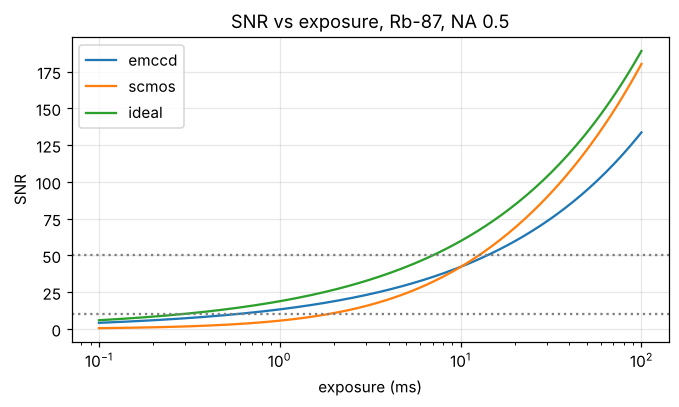

In [3]:
t = np.logspace(-1, 2, 200)
for cam in ("emccd", "scmos", "ideal"):
    plt.semilogx(t, [image(t_ms=x, cam=cam)["SNR"] for x in t], label=cam)
plt.axhline(10, ls=":", c="gray"); plt.axhline(50, ls=":", c="gray")
plt.xlabel("exposure (ms)"); plt.ylabel("SNR"); plt.legend(); plt.title("SNR vs exposure, Rb-87, NA 0.5")

## 3. Threshold and detection fidelity from a histogram
Given the bright and dark peak means and widths (from your own histogram), choose the threshold that minimises $P_\mathrm{miss}+P_\mathrm{false}$. The page offers presets; its default ⁸⁷Rb preset is shown here.

{'theta_opt': 242, 'SNR_hist': np.float64(16.827834691610306), 'p_miss': np.float64(1.4008602220956915e-40), 'p_false': np.float64(5.38080410591076e-41), 'infidelity': np.float64(9.694703163433837e-41)}

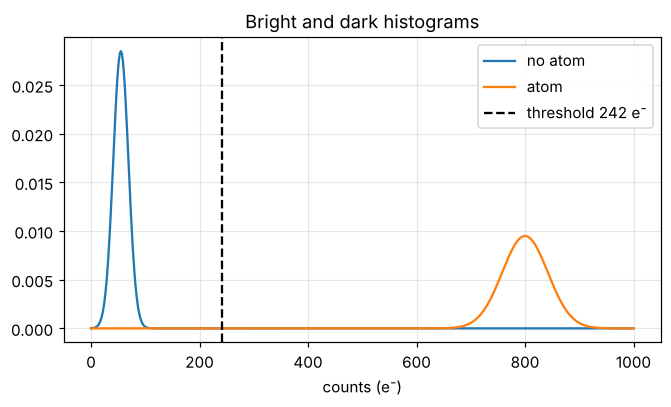

In [4]:
def hist_metrics(muB, sigB, muD, sigD, theta=None):
    lo, hi = max(0, min(muD, muB) - sigD), max(muD, muB) + sigB
    f = lambda th: norm.sf((muB - th) / sigB) + norm.sf((th - muD) / sigD)
    for _ in range(80):                         # ternary search, as on the page
        m1, m2 = lo + (hi - lo) / 3, hi - (hi - lo) / 3
        if f(m1) < f(m2): hi = m2
        else: lo = m1
    th_opt = round((lo + hi) / 2)
    th = th_opt if theta is None else theta
    p_miss, p_false = norm.sf((muB - th) / sigB), norm.sf((th - muD) / sigD)
    return dict(theta_opt=th_opt, SNR_hist=(muB - muD) / np.hypot(sigB, sigD), p_miss=p_miss, p_false=p_false,
                infidelity=(p_miss + p_false) / 2)

h = hist_metrics(800, 42, 55, 14)
print(h)
x = np.linspace(0, 1000, 600)
plt.plot(x, norm.pdf(x, 55, 14), label="no atom"); plt.plot(x, norm.pdf(x, 800, 42), label="atom")
plt.axvline(h["theta_opt"], c="k", ls="--", label=f"threshold {h['theta_opt']} e⁻")
plt.xlabel("counts (e⁻)"); plt.legend(); plt.title("Bright and dark histograms")

**Beyond the page:** real dark peaks have a long tail from background and EMCCD clock-induced charge, so measured infidelities are far above these Gaussian estimates. Fit your own histogram (e.g. with a Poisson × gain model) before trusting numbers below 10⁻³.

## 4. Check against the page
Values shown at the page's defaults, read from the live page when this notebook was built.

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(r, theta_opt=h["theta_opt"], SNR_hist=h["SNR_hist"])
DECIMALS = dict(eta_pct=2, eta_geo_pct=2, SNR=1, t_SNR10_ms=2, t_SNR50_ms=2, var_shot=1, var_total=1, theta_opt=0, SNR_hist=2)
page = dict(R_sc=9.53e6, eta_pct=3.75, eta_geo_pct=6.70, N_scattered=47.7e3, N_detected=1.8e3, SNR=29.9,
            t_SNR10_ms=0.56, t_SNR50_ms=13.99, var_shot=3582.3, var_total=3583.3, theta_opt=242, SNR_hist=16.83)
check(ours, page, rel=0.03)

        R_sc: notebook 9.527e+06    page 9.53e+06   OK
     eta_pct: notebook 3.751        page 3.75       OK
 eta_geo_pct: notebook 6.699        page 6.7        OK
 N_scattered: notebook 4.775e+04    page 47700      OK
  N_detected: notebook 1791         page 1800       OK
         SNR: notebook 29.92        page 29.9       OK
  t_SNR10_ms: notebook 0.5598       page 0.56       OK
  t_SNR50_ms: notebook 13.99        page 13.99      OK
    var_shot: notebook 3582         page 3582.3     OK
   var_total: notebook 3583         page 3583.3     OK
   theta_opt: notebook 242          page 242        OK
    SNR_hist: notebook 16.83        page 16.83      OK
All values match the page.